<a href="https://colab.research.google.com/github/MarcoMaceda/Pl1/blob/main/Dl_P1_Francisco_Marco.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
# 1. Importar as bibliotecas necessárias e montar o Google Drive
from google.colab import drive
import tensorflow as tf
import os
import random
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from collections import Counter
from PIL import Image
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import hashlib
import itertools
import pandas as pd
from sklearn.model_selection import train_test_split

# Vai pedir-te para autorizares o acesso ao teu Drive
drive.mount('/content/drive')



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Classes encontradas (4): ['jerry', 'tom', 'tom_jerry_0', 'tom_jerry_1']

Classe 'jerry': 1240 imagens
Classe 'tom': 1930 imagens
Classe 'tom_jerry_0': 1525 imagens
Classe 'tom_jerry_1': 780 imagens


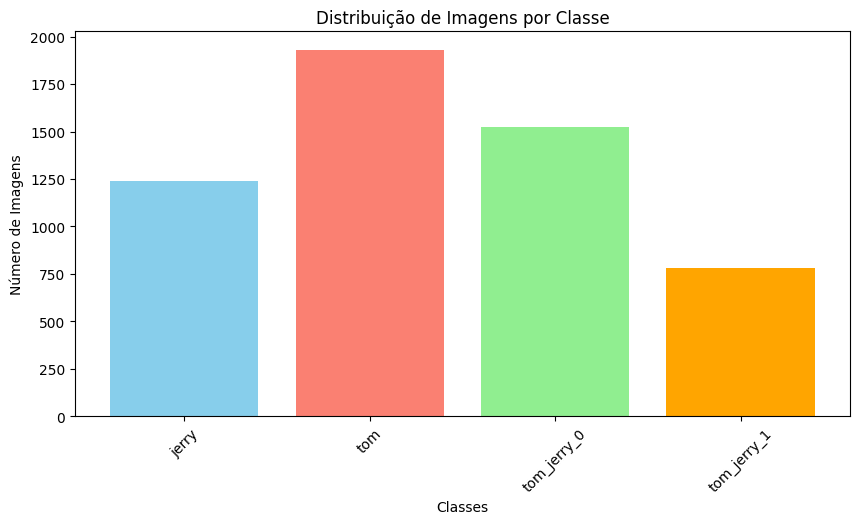

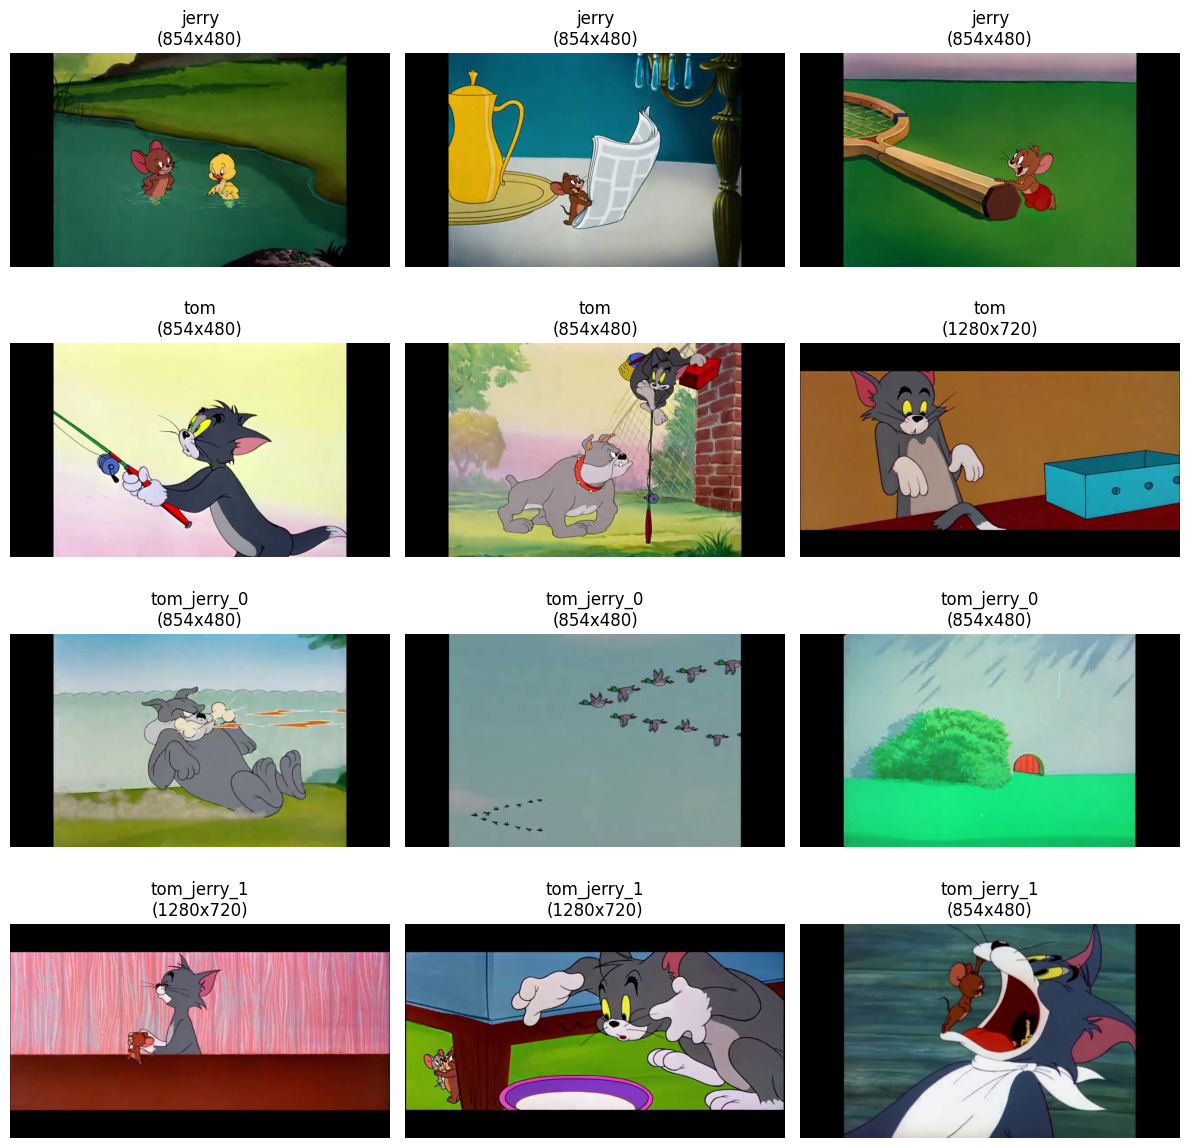

In [14]:
# Definir o caminho para a pasta do dataset no teu Drive
dataset_path = '/content/drive/MyDrive/p1/tom_and_jerry/tom_and_jerry'

# Obter o nome das classes (ignorar ficheiros escondidos como .ipynb_checkpoints)
classes = [d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d))]
classes.sort()

print(f"Classes encontradas ({len(classes)}): {classes}\n")

# Contar o número de imagens por classe
class_counts = {}
for class_name in classes:
    class_path = os.path.join(dataset_path, class_name)
    # Conta apenas ficheiros (exclui subpastas acidentais)
    num_images = len([f for f in os.listdir(class_path) if os.path.isfile(os.path.join(class_path, f))])
    class_counts[class_name] = num_images

# Mostrar distribuição
for class_name, count in class_counts.items():
    print(f"Classe '{class_name}': {count} imagens")

# Gráfico de barras da distribuição das classes
plt.figure(figsize=(10, 5))
plt.bar(class_counts.keys(), class_counts.values(), color=['skyblue', 'salmon', 'lightgreen', 'orange'])
plt.title('Distribuição de Imagens por Classe')
plt.xlabel('Classes')
plt.ylabel('Número de Imagens')
plt.xticks(rotation=45)
plt.show()

# Visualizar amostras aleatórias de cada classe
num_samples = 3 # Número de imagens a mostrar por classe
plt.figure(figsize=(12, 3 * len(classes)))

for i, class_name in enumerate(classes):
    class_path = os.path.join(dataset_path, class_name)
    all_images = [f for f in os.listdir(class_path) if os.path.isfile(os.path.join(class_path, f))]

    # Escolhe imagens aleatórias
    random_images = random.sample(all_images, min(num_samples, len(all_images)))

    for j, img_name in enumerate(random_images):
        img_path = os.path.join(class_path, img_name)
        img = mpimg.imread(img_path)

        # Posição no subplot
        plt.subplot(len(classes), num_samples, i * num_samples + j + 1)
        plt.imshow(img)

        # Obter resolução real da imagem
        with Image.open(img_path) as p_img:
            width, height = p_img.size

        plt.title(f"{class_name}\n({width}x{height})")
        plt.axis('off')

plt.tight_layout()
plt.show()

In [15]:
# Criar um DataFrame com os caminhos de todas as imagens e respetivas classes
data = []
classes = [d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d))]

print("A recolher caminhos das imagens...")
for class_name in classes:
    class_path = os.path.join(dataset_path, class_name)
    for img_name in os.listdir(class_path):
        img_path = os.path.join(class_path, img_name)
        if os.path.isfile(img_path):
            data.append({"path": img_path, "class": class_name})

df = pd.DataFrame(data)

# Calcular o MD5 para cada imagem
def compute_md5(file_path):
    with open(file_path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

print("A calcular hashes MD5... (isto pode demorar um pouco dependendo do tamanho do dataset)")
df["md5"] = df["path"].apply(compute_md5)

# Aplicar a tua lógica de Sets para verificar intersecções ENTRE AS CLASSES
# (Idealmente, as intersecções devem ser todas 0)
S = {c: set(df[df["class"] == c]["md5"]) for c in classes}

print("\n--- 🔍 VERIFICAÇÃO DE SOBREPOSIÇÃO ENTRE CLASSES ---")
# itertools.combinations gera todos os pares possíveis entre as tuas 4 classes
for c1, c2 in itertools.combinations(classes, 2):
    overlap = len(S[c1] & S[c2])
    print(f"Sobreposição entre '{c1}' e '{c2}': {overlap} imagens partilhadas")
    if overlap > 0:
        print(f"   -> ⚠️ ALERTA: Tens imagens repetidas em classes diferentes!")

# Verificar duplicados GERAIS (incluindo repetidas dentro da própria classe)
total_images = len(df)
unique_hashes = df["md5"].nunique()
duplicates_count = total_images - unique_hashes

print("\n--- 🗑️ VERIFICAÇÃO DE DUPLICADOS GERAIS ---")
print(f"Total de imagens processadas: {total_images}")
print(f"Imagens únicas reais: {unique_hashes}")
print(f"Total de imagens duplicadas (para remover): {duplicates_count}")

# Opcional: Mostrar e preparar código para apagar os duplicados
if duplicates_count > 0:
    # Mostra ficheiros que partilham o mesmo MD5
    duplicadas_df = df[df.duplicated(subset=['md5'], keep=False)].sort_values(by='md5')
    print("\nExemplo de ficheiros duplicados encontrados:")
    print(duplicadas_df[['class', 'path']].head(6))


A recolher caminhos das imagens...
A calcular hashes MD5... (isto pode demorar um pouco dependendo do tamanho do dataset)

--- 🔍 VERIFICAÇÃO DE SOBREPOSIÇÃO ENTRE CLASSES ---
Sobreposição entre 'tom_jerry_1' e 'jerry': 0 imagens partilhadas
Sobreposição entre 'tom_jerry_1' e 'tom': 0 imagens partilhadas
Sobreposição entre 'tom_jerry_1' e 'tom_jerry_0': 0 imagens partilhadas
Sobreposição entre 'jerry' e 'tom': 0 imagens partilhadas
Sobreposição entre 'jerry' e 'tom_jerry_0': 0 imagens partilhadas
Sobreposição entre 'tom' e 'tom_jerry_0': 0 imagens partilhadas

--- 🗑️ VERIFICAÇÃO DE DUPLICADOS GERAIS ---
Total de imagens processadas: 5475
Imagens únicas reais: 5475
Total de imagens duplicadas (para remover): 0


In [16]:
# Se quiseres apagar os duplicados (mantendo apenas o primeiro exemplar):
df_to_keep = df.drop_duplicates(subset=['md5'], keep='first')
images_to_delete = df[~df.index.isin(df_to_keep.index)]['path']
for path_to_delete in images_to_delete:
    os.remove(path_to_delete)
print(f"\nForam apagadas {len(images_to_delete)} imagens duplicadas.")


Foram apagadas 0 imagens duplicadas.


In [17]:
# Definir a camada de normalização
# 1./255 transforma os valores de 0-255 para floats de 0.0 a 1.0
normalizer = tf.keras.layers.Rescaling(1./255, input_shape=(224, 224, 3))

# Exemplo de como começa a tua CNN Baseline:
model = tf.keras.Sequential([
  normalizer, # <- A normalização acontece aqui, na entrada do modelo

  # Seguido das tuas camadas convolucionais normais:
  tf.keras.layers.Conv2D(32, 3, activation='relu'),
  tf.keras.layers.MaxPooling2D(),
  # ... (resto do modelo)
  ])

print("Camada de normalização adicionada ao modelo com sucesso!")

Camada de normalização adicionada ao modelo com sucesso!


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [18]:
# Definir as dimensões desejadas
img_height = 128
img_width = 128

model = tf.keras.Sequential([
  # Redimensionar para 128x128
  tf.keras.layers.Resizing(img_height, img_width, input_shape=(None, None, 3)),

  # Normalizar de 0-255 para 0-1
  tf.keras.layers.Rescaling(1./255),

  # As tuas camadas Convolucionais
  tf.keras.layers.Conv2D(32, 3, padding='same', activation='relu'),
  tf.keras.layers.MaxPooling2D(),
  # ... (resto do modelo)
])

print("O modelo agora redimensiona e normaliza automaticamente todas as imagens de entrada!")

O modelo agora redimensiona e normaliza automaticamente todas as imagens de entrada!


In [19]:
# Recolher todos os caminhos das imagens e as respetivas classes
data = []
classes = sorted([d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d))])
class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}

for class_name in classes:
    class_path = os.path.join(dataset_path, class_name)
    for img_name in os.listdir(class_path):
        img_path = os.path.join(class_path, img_name)
        if os.path.isfile(img_path):
            data.append({"path": img_path, "label": class_to_idx[class_name]})

df = pd.DataFrame(data)

# Primeira Divisão: 70% Treino e 30% Temporário (para depois dividir em Val/Test)
# O argumento 'stratify=df["label"]' é o que garante o equilíbrio das classes!
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

# Segunda Divisão: Dividir os 30% temporários a meio (15% Validação / 15% Teste)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50, # 50% de 30% = 15% do total
    random_state=42,
    stratify=temp_df["label"]
)

print(f"Total de imagens: {len(df)}")
print(f"Treino (70%): {len(train_df)} imagens")
print(f"Validação (15%): {len(val_df)} imagens")
print(f"Teste (15%): {len(test_df)} imagens\n")

# Criar função para carregar, redimensionar (128x128) e normalizar (0-1) na hora
def process_path(file_path, label):
    # Ler o ficheiro físico
    img = tf.io.read_file(file_path)
    # Converter para imagem (RGB)
    img = tf.image.decode_jpeg(img, channels=3)
    # Redimensionar como pediste antes
    img = tf.image.resize(img, [128, 128])
    # Normalizar de 0-255 para 0-1
    img = img / 255.0
    return img, label

# Converter os DataFrames em Datasets nativos do TensorFlow (muito mais rápido e eficiente)
def create_tf_dataset(dataframe, batch_size=32, is_training=False):
    paths = dataframe["path"].values
    labels = dataframe["label"].values

    # Criar um dataset a partir dos caminhos
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if is_training:
        ds = ds.shuffle(buffer_size=len(dataframe)) # Baralhar só no treino

    # Aplicar o processamento (com AUTOTUNE para usar CPU em paralelo)
    AUTOTUNE = tf.data.AUTOTUNE
    ds = ds.map(process_path, num_parallel_calls=AUTOTUNE)

    # Agrupar em batches e fazer prefetch
    ds = ds.batch(batch_size).prefetch(buffer_size=AUTOTUNE)
    return ds

# Pronto! Estes são os objetos que vais usar no model.fit() e model.evaluate()
train_ds = create_tf_dataset(train_df, batch_size=32, is_training=True)
val_ds = create_tf_dataset(val_df, batch_size=32, is_training=False)
test_ds = create_tf_dataset(test_df, batch_size=32, is_training=False)

print("Datasets de TensorFlow criados com sucesso e prontos para treino!")

Total de imagens: 5475
Treino (70%): 3832 imagens
Validação (15%): 821 imagens
Teste (15%): 822 imagens

Datasets de TensorFlow criados com sucesso e prontos para treino!


In [20]:
# Definir os parâmetros baseados nos passos anteriores
img_height = 128
img_width = 128
canais = 3 # RGB
num_classes = len(classes) # Pega automaticamente nas 4 classes que detetámos antes

print(f"A criar CNN Baseline para {num_classes} classes com entrada ({img_height}, {img_width}, {canais})...")

# Construir a Arquitetura da CNN
model = tf.keras.Sequential([
    # Camada de entrada + 1ª Convolução (Extrai características simples como linhas e bordas)
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(img_height, img_width, canais)),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)), # Reduz a imagem a metade
    tf.keras.layers.Dropout(0.25), # <-- NOVO: Desliga 25% dos neurónios aqui

    # 2ª Convolução (Extrai características intermédias como texturas)
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
    tf.keras.layers.Dropout(0.25), # <-- NOVO: Desliga 25% dos neurónios aqui

    # 3ª Convolução (Extrai características complexas/padrões de partes dos objetos)
    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
    tf.keras.layers.Dropout(0.25), # <-- NOVO: Desliga 25% dos neurónios aqui

    # Achatar os dados para passar para as camadas densas (redes neurais clássicas)
    tf.keras.layers.Flatten(),

    # Camada totalmente conectada (Processa os padrões encontrados)
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),  # Dropout forte antes da saída (já existia)

    # Dropout (Apaga 50% dos neurónios aleatoriamente no treino para evitar Overfitting)
    tf.keras.layers.Dropout(0.5),

    # Camada de Saída
    # Número de neurónios = número de classes. Ativação 'softmax' dá-nos a percentagem/probabilidade para cada classe.
    tf.keras.layers.Dense(num_classes, activation='softmax')
])

# Mostrar o resumo da arquitetura
model.summary()

# Compilar o Modelo
model.compile(
    optimizer='adam', # Otimizador padrão e muito eficiente
    loss='sparse_categorical_crossentropy', # Usamos 'sparse' porque as nossas labels são inteiros (0, 1, 2, 3) e não one-hot encoded
    metrics=['accuracy']
)

# Treinar o Modelo
epochs = 30 # Podes ajustar este valor. 15 é um bom ponto de partida para uma baseline

print("\n🚀 A iniciar o treino...")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)

A criar CNN Baseline para 4 classes com entrada (128, 128, 3)...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,156 (12.61 MB)

 Trainable params: 3,305,156 (12.61 MB)

 Non-trainable params: 0 (0.00 B)


🚀 A iniciar o treino...
Epoch 1/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 34s 192ms/step - accuracy: 0.3288 - loss: 1.3742 - val_accuracy: 0.3520 - val_loss: 1.3354
Epoch 2/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 27s 152ms/step - accuracy: 0.3687 - loss: 1.3149 - val_accuracy: 0.4665 - val_loss: 1.2415
Epoch 3/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 23s 177ms/step - accuracy: 0.4428 - loss: 1.2238 - val_accuracy: 0.4957 - val_loss: 1.1601
Epoch 4/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 20s 169ms/step - accuracy: 0.5117 - loss: 1.1042 - val_accuracy: 0.5761 - val_loss: 0.9841
Epoch 5/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 18s 149ms/step - accuracy: 0.5530 - loss: 0.9993 - val_accuracy: 0.6017 - val_loss: 0.9169
Epoch 6/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 20s 167ms/step - accuracy: 0.6059 - loss: 0.9109 - val_accuracy: 0.6041 - val_loss: 0.8955
Epoch 7/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 19s 158ms/step - accuracy: 0.6334 - loss: 0.8642 - val_accuracy: 0.6857 - val_loss: 0.7862
Epoch 8/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 17s 143ms/step - a

A iniciar o processo de treino com mitigação de overfitting...
Epoch 1/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 27s 167ms/step - accuracy: 0.9001 - loss: 0.2519 - val_accuracy: 0.8575 - val_loss: 0.5776
Epoch 2/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 16s 134ms/step - accuracy: 0.8951 - loss: 0.2539 - val_accuracy: 0.8538 - val_loss: 0.6010
Epoch 3/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 17s 143ms/step - accuracy: 0.9008 - loss: 0.2521 - val_accuracy: 0.8551 - val_loss: 0.6189
Epoch 4/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 19s 133ms/step - accuracy: 0.8974 - loss: 0.2424 - val_accuracy: 0.8648 - val_loss: 0.5762
Epoch 5/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 21s 135ms/step - accuracy: 0.9061 - loss: 0.2276 - val_accuracy: 0.8417 - val_loss: 0.6278
Epoch 6/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 16s 134ms/step - accuracy: 0.9008 - loss: 0.2416 - val_accuracy: 0.8441 - val_loss: 0.6644
Epoch 7/30
120/120 ━━━━━━━━━━━━━━━━━━━━ 22s 150ms/step - accuracy: 0.8977 - loss: 0.2629 - val_accuracy: 0.8477 - val_loss: 0.6823
Epoch 8/30
120/120 ━

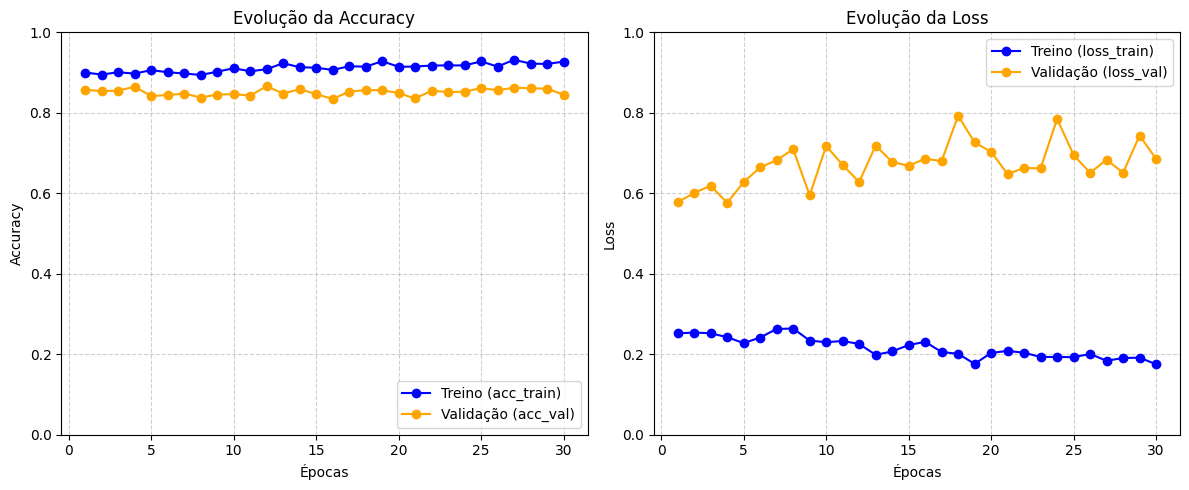

In [22]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Executar o treino
epochs = 30
print("A iniciar o processo de treino com mitigação de overfitting...")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)

# Extrair as métricas guardadas no dicionário history
acc_train = history.history['accuracy']
acc_val = history.history['val_accuracy']
loss_train = history.history['loss']
loss_val = history.history['val_loss']

# Definir o eixo do X (número de épocas)
intervalo_epocas = range(1, epochs + 1)

# Desenhar os gráficos de desempenho
plt.figure(figsize=(12, 5))

# Gráfico da Accuracy (Precisão)
plt.subplot(1, 2, 1)
plt.plot(intervalo_epocas, acc_train, label='Treino (acc_train)', color='blue', marker='o')
plt.plot(intervalo_epocas, acc_val, label='Validação (acc_val)', color='orange', marker='o')
plt.title('Evolução da Accuracy')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.ylim(0, 1) # Fixa a escala do eixo Y de 0 a 1
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)

# Gráfico da Loss (Perda/Erro)
plt.subplot(1, 2, 2)
plt.plot(intervalo_epocas, loss_train, label='Treino (loss_train)', color='blue', marker='o')
plt.plot(intervalo_epocas, loss_val, label='Validação (loss_val)', color='orange', marker='o')
plt.title('Evolução da Loss')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.ylim(0, 1)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

🔍 A avaliar o modelo no Dataset de Teste (15% guardados)...
26/26 ━━━━━━━━━━━━━━━━━━━━ 4s 151ms/step - accuracy: 0.8625 - loss: 0.6381

--- 🏆 RESULTADO FINAL ---
Loss (Erro): 0.6381
Accuracy (Precisão Global): 86.25%

A gerar previsões para a Matriz de Confusão...
26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 101ms/step


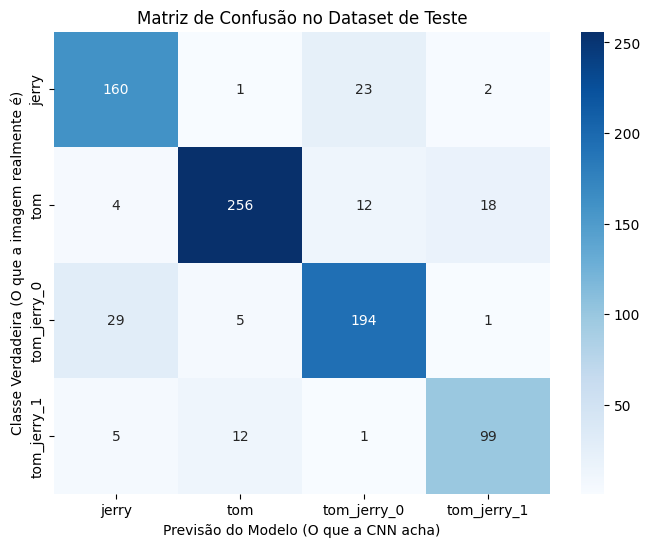


📊 Relatório Detalhado de Classificação:
              precision    recall  f1-score   support

       jerry       0.81      0.86      0.83       186
         tom       0.93      0.88      0.91       290
 tom_jerry_0       0.84      0.85      0.85       229
 tom_jerry_1       0.82      0.85      0.84       117

    accuracy                           0.86       822
   macro avg       0.85      0.86      0.86       822
weighted avg       0.86      0.86      0.86       822



In [23]:
# Avaliação global simples (Accuracy e Loss gerais)
print("🔍 A avaliar o modelo no Dataset de Teste (15% guardados)...")
test_loss, test_acc = model.evaluate(test_ds)

print(f"\n--- 🏆 RESULTADO FINAL ---")
print(f"Loss (Erro): {test_loss:.4f}")
print(f"Accuracy (Precisão Global): {test_acc * 100:.2f}%\n")

# Obter as previsões detalhadas para cada imagem do teste
print("A gerar previsões para a Matriz de Confusão...")
# O model.predict devolve as probabilidades para cada classe
previsoes = model.predict(test_ds)
# np.argmax escolhe a classe com maior probabilidade
classes_previstas = np.argmax(previsoes, axis=1)

# Extrair as labels verdadeiras iterando pelo dataset de teste
classes_verdadeiras = np.concatenate([y.numpy() for x, y in test_ds], axis=0)

# Desenhar a Matriz de Confusão
matriz_confusao = confusion_matrix(classes_verdadeiras, classes_previstas)

plt.figure(figsize=(8, 6))
# Usamos os nomes das classes que definimos lá atrás para os eixos ficarem bonitos
sns.heatmap(matriz_confusao, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes)
plt.title('Matriz de Confusão no Dataset de Teste')
plt.xlabel('Previsão do Modelo (O que a CNN acha)')
plt.ylabel('Classe Verdadeira (O que a imagem realmente é)')
plt.show()

# Mostrar o Relatório de Classificação (Precision, Recall, F1-Score)
print("\n📊 Relatório Detalhado de Classificação:")
print(classification_report(classes_verdadeiras, classes_previstas, target_names=classes))